# 02 · Análise Exploratória (EDA)
Objetivo: entender **como, quando e onde** a demanda acontece, identificando
tendência, sazonalidade, efeito de promoções, feriados e diferenças entre lojas
e categorias — e traduzir cada padrão em **decisões gerenciais**.

## 1. Setup e carga
Importamos as funções do módulo `src/data.py`, carregamos os arquivos Parquet
(segundos, contra minutos do CSV) e enriquecemos as vendas com atributos de
produto (família, perecível) e loja (cidade, tipo, cluster).

In [8]:
import sys
sys.path.append("..")  # permite importar a pasta src/

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_processed, enrich_sales

# Estilo padrão dos gráficos e pasta onde salvaremos as figuras
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
FIG = Path("../reports/figures")

# Carga dos dados tratados
data = load_processed()
items, stores, oil, holidays, trans = (data[k] for k in
                                       ["items", "stores", "oil", "holidays", "transactions"])

# Vendas enriquecidas com produto e loja; liberamos a tabela original da memória
df = enrich_sales(data["train_2017"], items, stores)
del data
print(df.shape)
df.head()

(23808261, 12)


,date,store_nbr,item_nbr,unit_sales,onpromotion,family,class,perishable,city,state,store_type,cluster
0,2017-01-01,25,99197,1.0,0,GROCERY I,1067,0,Salinas,Santa Elena,D,1
1,2017-01-01,25,103665,7.0,0,BREAD/BAKERY,2712,1,Salinas,Santa Elena,D,1
2,2017-01-01,25,105574,1.0,0,GROCERY I,1045,0,Salinas,Santa Elena,D,1
3,2017-01-01,25,105857,4.0,0,GROCERY I,1092,0,Salinas,Santa Elena,D,1
4,2017-01-01,25,106716,2.0,0,GROCERY I,1032,0,Salinas,Santa Elena,D,1


## 2. Visão geral do negócio
Números-chave do período analisado: tamanho da operação (lojas, itens, famílias),
volume vendido e participação de vendas em promoção.

In [9]:
kpis = {
    "Período": f"{df['date'].min():%d/%m/%Y} a {df['date'].max():%d/%m/%Y}",
    "Lojas": df["store_nbr"].nunique(),
    "Itens vendidos": df["item_nbr"].nunique(),
    "Famílias de produtos": df["family"].nunique(),
    "Unidades vendidas": f"{df['unit_sales'].sum():,.0f}",
    "Registros (loja × item × dia)": f"{len(df):,}",
    "% de registros em promoção": f"{df['onpromotion'].mean():.1%}",
    "% de unidades perecíveis": f"{df.loc[df['perishable'] == 1, 'unit_sales'].sum() / df['unit_sales'].sum():.1%}",
}
pd.Series(kpis, name="Valor").to_frame()

,Valor
Período,01/01/2017 a 15/08/2017
Lojas,54
Itens vendidos,4018
Famílias de produtos,33
Unidades vendidas,"194,242,448"
Registros (loja × item × dia),"23,808,261"
% de registros em promoção,11.5%
% de unidades perecíveis,33.3%


### 💡 Insights — Visão geral

**Dimensão da operação (01/01 a 15/08/2017 — 227 dias)**
- **54 lojas**, **4.018 itens** ativos em **33 famílias** de produtos.
- **194 milhões de unidades** vendidas ≈ **856 mil unidades/dia** na rede,
  ou ~15,8 mil unidades/dia por loja.
- Em média, cada registro (loja × item × dia) vende **~8 unidades**.

**Pontos de atenção**
1. **Demanda esparsa:** existem 54 × 4.018 ≈ 217 mil combinações loja-item, mas
   apenas ~105 mil aparecem com venda a cada dia (**~48%**). Ou seja, em mais da
   metade dos dias um item não vende em uma loja — ou o dado de venda zero não foi
   registrado. Na modelagem, os dias ausentes serão preenchidos com **zero**.
2. **Perecíveis = 1/3 do volume (33,3%):** são os itens de maior risco de perda
   (vencimento) e recebem **peso 1,25** na métrica oficial (NWRMSLE).
3. **Promoções em 11,5% dos registros:** volume relevante para medir quanto
   a promoção realmente aumenta as vendas (*uplift*).

**Decisões gerenciais**
- **Perecíveis exigem previsão mais precisa e reposição mais frequente** —
  errar para cima gera descarte; errar para baixo, ruptura.
- **Itens de giro baixo/intermitente** pedem política de estoque diferente
  (estoque mínimo e reposição sob demanda) dos itens de alto giro.
- A escala (~856 mil unidades/dia) mostra que **1% de melhoria na previsão**
  equivale a ~8,5 mil unidades/dia melhor alocadas na rede.

## 3. Tendência de longo prazo (2013–2017)
Usamos a tabela `transactions` (nº de cupons por loja/dia), que cobre todo o
histórico e é leve. A **média móvel de 28 dias** suaviza o ruído diário e revela
a tendência; picos e vales mostram sazonalidade anual e eventos atípicos.

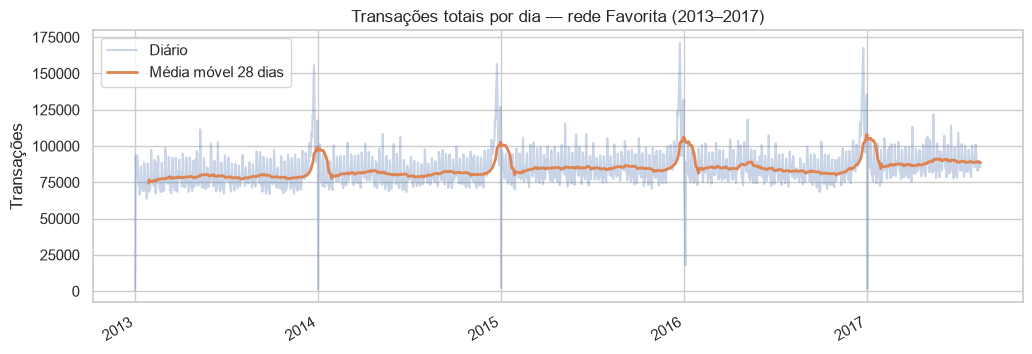

,Média diária,Variação vs ano anterior
date,,
2013,79965.0,—
2014,82437.0,+3.1%
2015,86023.0,+4.4%
2016,85544.0,-0.6%
2017,88106.0,+3.0%


In [10]:
# Total de transações por dia em toda a rede
daily_tx = trans.groupby("date")["transactions"].sum()

fig, ax = plt.subplots()
daily_tx.plot(ax=ax, alpha=0.3, label="Diário")
daily_tx.rolling(28).mean().plot(ax=ax, color="C1", lw=2, label="Média móvel 28 dias")
ax.set(title="Transações totais por dia — rede Favorita (2013–2017)",
       xlabel="", ylabel="Transações")
ax.legend()
plt.savefig(FIG / "02_tendencia_transacoes.png", dpi=120, bbox_inches="tight")
plt.show()

# Média diária de transações por ano (2017 vai só até agosto)
yearly = daily_tx.groupby(daily_tx.index.year).mean()
pd.DataFrame({"Média diária": yearly.round(0),
              "Variação vs ano anterior": yearly.pct_change().map(lambda x: f"{x:+.1%}" if pd.notna(x) else "—")})

### 💡 Insights — Tendência de longo prazo

**O que os dados mostram**
1. **Demanda estável com crescimento moderado:** a média diária passou de ~80 mil
   transações (2013) para ~88 mil (2017), crescimento acumulado de **~10%** (≈ 2,5% ao ano).
2. **Dezembro é o grande pico do ano:** a média móvel sobe de ~85 mil para ~105 mil
   (**+20 a 25%**), e os dias de pico próximos ao Natal chegam a **~2x** um dia normal.
3. **Queda brusca na virada do ano:** 25/12 e 01/01 têm vendas próximas de zero
   (lojas fechadas), seguidos de um janeiro mais fraco.
4. **2016 foi o único ano de retração (-0,6%)**, coincidindo com a recessão
   econômica do Equador e o terremoto de abril/2016.
5. Fora de dezembro, a série é **bastante estável** — bom sinal para previsibilidade.

> Obs.: 2017 cobre só jan–ago (sem o pico de dezembro), então o +3,0% tende a
> **subestimar** o crescimento real do ano.

**Decisões gerenciais**
- **Planejamento de fim de ano:** antecipar compras em outubro/novembro e reforçar
  estoque e equipe em ~20–25% em dezembro, com atenção especial à semana do Natal.
- **Janeiro:** reduzir pedidos de perecíveis na 1ª quinzena para evitar perdas
  após o pico.
- **Orçamento anual:** usar ~3% de crescimento como cenário-base de volume.
- **Modelagem:** dias de loja fechada (25/12 e 01/01) devem ser tratados como
  exceção, e não como "demanda zero".

## 4. Sazonalidade semanal
Calculamos a venda média de cada dia da semana em 2017 e transformamos em um
**índice (média = 100)**: valores acima de 100 indicam dias mais fortes que a média.
Excluímos 01/01, quando as lojas ficam praticamente fechadas.

C:\Users\elies\AppData\Local\Temp\ipykernel_9964\2274794432.py:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = daily.groupby(daily.index.dayofweek).mean()


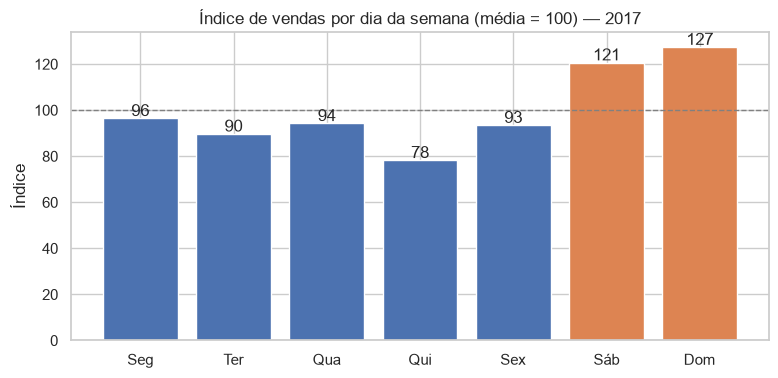

In [11]:
# Vendas totais por dia (2017), sem o dia 01/01 (lojas fechadas)
daily = df.groupby("date")["unit_sales"].sum()
daily = daily[daily.index != "2017-01-01"]

# Média por dia da semana -> índice (média = 100)
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
dow = daily.groupby(daily.index.dayofweek).mean()
dow_idx = dow / dow.mean() * 100
dow_idx.index = dias

fig, ax = plt.subplots(figsize=(9, 4))
cores = ["C1" if v >= 100 else "C0" for v in dow_idx]
ax.bar(dow_idx.index, dow_idx.values, color=cores)
ax.axhline(100, color="gray", ls="--", lw=1)
for i, v in enumerate(dow_idx):
    ax.text(i, v + 1, f"{v:.0f}", ha="center")
ax.set(title="Índice de vendas por dia da semana (média = 100) — 2017", ylabel="Índice")
plt.savefig(FIG / "02_sazonalidade_semanal.png", dpi=120, bbox_inches="tight")
plt.show()

### 💡 Insights — Sazonalidade semanal

**O que os dados mostram**
1. **O fim de semana concentra a demanda:** sábado (121) e domingo (127) ficam
   21% e 27% acima da média. Juntos, respondem por **~35% do volume semanal**
   em apenas 2 dos 7 dias (28,6%).
2. **Quinta-feira é o dia mais fraco (78)** — o domingo vende **~1,6x** mais que
   a quinta.
3. **Segunda (96) é o melhor dia útil**, provavelmente pela reposição das
   compras após o fim de semana.

**Decisões gerenciais**
- **Reposição e logística:** entregas de perecíveis e abastecimento de gôndolas
  devem estar concluídos **até sexta**, antecipando o pico do fim de semana.
- **Escala de equipe:** reforçar caixas e repositores no sábado e domingo;
  usar a **quinta-feira** para inventário, recebimento de mercadorias e manutenção.
- **Promoções táticas:** dias fracos (quinta) são candidatos a ações que
  suavizem a demanda e melhorem o uso da capacidade da loja.
- **Modelagem:** o dia da semana é uma *feature* obrigatória — a mesma loja/item
  pode vender ~60% a mais no domingo do que na quinta.

## 5. Efeito do dia de pagamento
No Equador, o setor público paga salários **quinzenalmente, nos dias 15 e no último
dia do mês**. Investigamos se isso altera a demanda ao longo do mês — o que é
diretamente relevante para as previsões por quinzena.

Para não confundir com o efeito do dia da semana, cada dia é dividido pela média
do seu dia da semana (**ajuste semanal**) antes de calcular o índice.

C:\Users\elies\AppData\Local\Temp\ipykernel_9964\995280101.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  daily_adj = daily / dow.reindex(daily.index.dayofweek).values


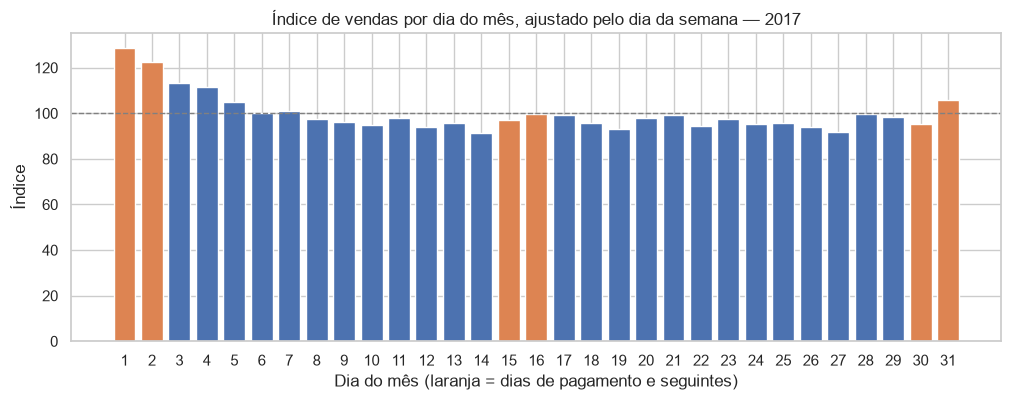

,Índice
1ª quinzena (1–15),102.900002
2ª quinzena (16–fim),96.800003


In [12]:
# Remove o efeito do dia da semana: venda do dia / média do seu dia da semana
daily_adj = daily / dow.reindex(daily.index.dayofweek).values

# Índice por dia do mês (média = 100)
dom_idx = daily_adj.groupby(daily_adj.index.day).mean()
dom_idx = dom_idx / dom_idx.mean() * 100

fig, ax = plt.subplots()
dias_pagto = {1, 2, 15, 16, 30, 31}
cores = ["C1" if d in dias_pagto else "C0" for d in dom_idx.index]
ax.bar(dom_idx.index, dom_idx.values, color=cores)
ax.axhline(100, color="gray", ls="--", lw=1)
ax.set_xticks(range(1, 32))
ax.set(title="Índice de vendas por dia do mês, ajustado pelo dia da semana — 2017",
       xlabel="Dia do mês (laranja = dias de pagamento e seguintes)", ylabel="Índice")
plt.savefig(FIG / "02_efeito_pagamento.png", dpi=120, bbox_inches="tight")
plt.show()

# Comparação direta: 1ª quinzena x 2ª quinzena
quinzena = np.where(daily_adj.index.day <= 15, "1ª quinzena (1–15)", "2ª quinzena (16–fim)")
(daily_adj.groupby(quinzena).mean() / daily_adj.mean() * 100).round(1).to_frame("Índice")

### 💡 Insights — Efeito do dia de pagamento

**O que os dados mostram**
1. **O início do mês é o período mais forte:** os dias **1 e 2** ficam **22–28%**
   acima da média, e o efeito se estende até o dia 5 (113 → 105).
2. **O pagamento do dia 15 tem efeito fraco:** os dias 15 e 16 ficam praticamente
   na média (97–99), sem pico visível. O consumo parece reagir mais ao pagamento
   de fim/início de mês (setor público **e** privado).
3. **A 1ª quinzena vende ~6% mais que a 2ª** (índice 102,9 contra 96,8), mesmo
   após remover o efeito do dia da semana.
4. A demanda vai "secando" ao longo do mês e só se recupera no dia 31/1º.

> Obs.: cada dia do mês tem só ~7 observações em 2017 (e o dia 31 apenas 4),
> então diferenças pequenas (±3 pontos) devem ser lidas com cautela.

**Decisões gerenciais**
- **Estoque reforçado nos primeiros 5 dias do mês**, especialmente em itens de
  alto giro, para evitar ruptura no pico pós-pagamento.
- **Promoções na 2ª quinzena** (dias 18–29) podem estimular a demanda no período
  em que o orçamento das famílias está mais apertado.
- **Previsões por quinzena precisam desse ajuste:** um horizonte que inclui a
  virada do mês tende a ter volume maior que um que fica só no meio do mês.
- **Modelagem:** incluir *features* de calendário como "dia do mês",
  "dias desde o último pagamento" e uma marca para início de mês.

## 6. Famílias de produtos e curva ABC
Quais categorias concentram o volume? E quantos itens realmente importam?
- **Ranking de famílias** por participação nas unidades vendidas, destacando perecíveis.
- **Curva ABC (Pareto) dos itens:** classe **A** = itens que somam 80% do volume,
  **B** = próximos 15%, **C** = últimos 5%. É a base para diferenciar políticas
  de estoque por importância do item.

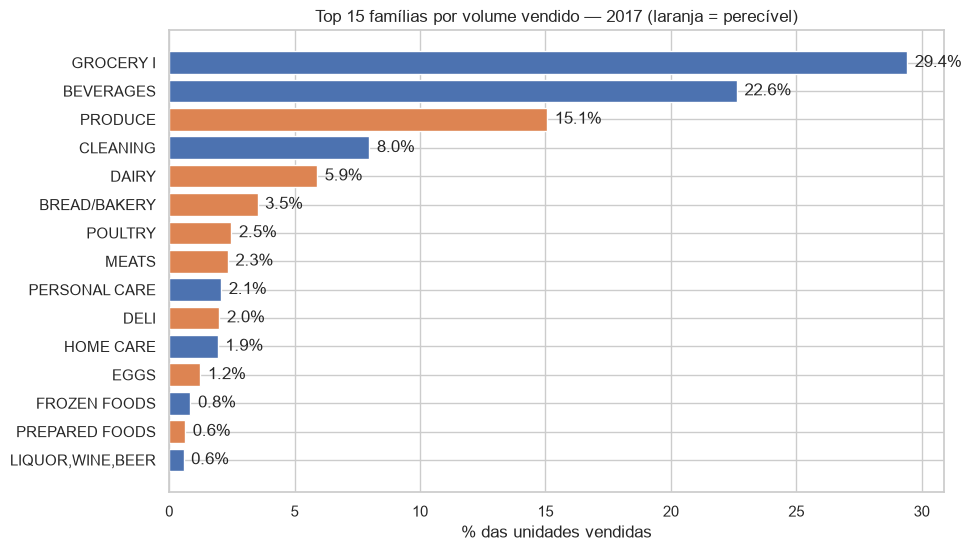

,unidades,itens,perecivel,participacao,acumulado
family,,,,,
GROCERY I,"57,155,096",1279,0,29.4%,29.4%
BEVERAGES,"43,959,720",601,0,22.6%,52.1%
PRODUCE,"29,275,728",306,1,15.1%,67.1%
CLEANING,"15,500,261",445,0,8.0%,75.1%
DAIRY,"11,455,870",242,1,5.9%,81.0%
BREAD/BAKERY,"6,840,462",134,1,3.5%,84.5%
POULTRY,"4,814,954",54,1,2.5%,87.0%
MEATS,"4,540,940",84,1,2.3%,89.3%
PERSONAL CARE,"4,029,869",152,0,2.1%,91.4%


In [13]:
# Volume, nº de itens e perecibilidade por família
fam = (df.groupby("family", observed=True)
         .agg(unidades=("unit_sales", "sum"),
              itens=("item_nbr", "nunique"),
              perecivel=("perishable", "max"))
         .astype({"unidades": "float64"})
         .sort_values("unidades", ascending=False))
fam["participacao"] = fam["unidades"] / fam["unidades"].sum()
fam["acumulado"] = fam["participacao"].cumsum()

# Gráfico: top 15 famílias (laranja = perecível)
top = fam.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
cores = ["C1" if p == 1 else "C0" for p in top["perecivel"]]
ax.barh(top.index.astype(str), top["participacao"] * 100, color=cores)
for i, v in enumerate(top["participacao"] * 100):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax.set(title="Top 15 famílias por volume vendido — 2017 (laranja = perecível)",
       xlabel="% das unidades vendidas")
plt.savefig(FIG / "02_familias.png", dpi=120, bbox_inches="tight")
plt.show()

fam.head(15).style.format({"unidades": "{:,.0f}", "participacao": "{:.1%}",
                           "acumulado": "{:.1%}"})

### 💡 Insights — Famílias de produtos

**O que os dados mostram**
1. **Alta concentração:** das 33 famílias, apenas **3** — **GROCERY I** <small>(mercearia)</small>,
   **BEVERAGES** <small>(bebidas)</small> e **PRODUCE** <small>(hortifrúti)</small> —
   respondem por **67% do volume**, e as **5 primeiras por 81%**.
2. **PRODUCE** <small>(hortifrúti)</small> **é o perecível crítico:** sozinho representa
   **15,1% do volume** e **~45% de todo o volume perecível**.
3. **Giro por item muito diferente entre famílias** (unidades vendidas ÷ nº de itens):

   | Família | Unid./item | Perecível |
   |---|---|---|
   | PRODUCE <small>(hortifrúti)</small> | ~96 mil | ✅ |
   | POULTRY <small>(aves/frango)</small> | ~89 mil | ✅ |
   | BEVERAGES <small>(bebidas)</small> | ~73 mil | ❌ |
   | GROCERY I <small>(mercearia)</small> | ~45 mil | ❌ |
   | PERSONAL CARE <small>(higiene pessoal)</small> | ~27 mil | ❌ |

   Hortifrúti e frango têm **poucos itens com giro altíssimo** — e vencem rápido.
4. **GROCERY I** <small>(mercearia)</small> e **BEVERAGES** <small>(bebidas)</small> são o
   "motor de volume" (**52%**), mas **não perecíveis**.

> Obs.: em famílias vendidas por peso — **PRODUCE** <small>(hortifrúti)</small>,
> **MEATS** <small>(carnes)</small> e **POULTRY** <small>(aves)</small> — `unit_sales`
> está em **kg**, então comparações de volume entre famílias são aproximadas.

**Decisões gerenciais**
- **Prioridade máxima de precisão em PRODUCE** <small>(hortifrúti)</small>,
  **POULTRY** <small>(aves)</small> **e DAIRY** <small>(laticínios)</small>: alto giro +
  perecibilidade = maior risco simultâneo de ruptura **e** de perda. Reposição
  diária ou em dias alternados, guiada pela previsão.
- **GROCERY I** <small>(mercearia)</small> **e BEVERAGES** <small>(bebidas)</small>
  comportam **estoque de segurança maior** com baixo risco de perda — a prioridade
  é **não faltar**.
- **Negociação com fornecedores:** concentrar esforço nas 5 famílias que somam
  81% do volume, onde ganhos de prazo e preço têm maior impacto.
- **Gestão por categoria:** famílias de cauda longa (< 1% do volume cada) podem
  ter sortimento revisto e reposição menos frequente.

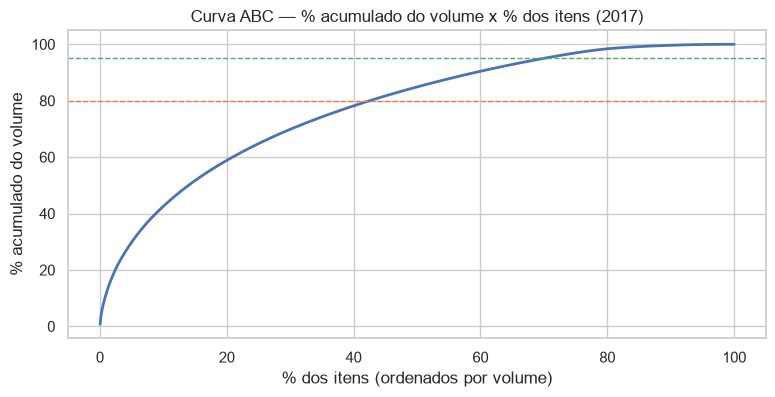

,itens,% dos itens,% do volume
unit_sales,,,
A,1708,42.5%,80.0%
B,1101,27.4%,15.0%
C,1209,30.1%,5.0%


In [14]:
# Volume por item, do maior para o menor, e participação acumulada
item_sales = (df.groupby("item_nbr")["unit_sales"].sum()
                .astype("float64").sort_values(ascending=False))
acum = item_sales.cumsum() / item_sales.sum()

# Classificação ABC: A = até 80%, B = 80–95%, C = 95–100%
abc = pd.cut(acum, bins=[0, 0.80, 0.95, 1.01], labels=["A", "B", "C"])

resumo = abc.value_counts().sort_index().to_frame("itens")
resumo["% dos itens"] = resumo["itens"] / resumo["itens"].sum()
resumo["% do volume"] = item_sales.groupby(abc, observed=True).sum() / item_sales.sum()

# Curva de Pareto
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(1, len(acum) + 1) / len(acum) * 100
ax.plot(x, acum.values * 100, lw=2)
ax.axhline(80, color="C1", ls="--", lw=1)
ax.axhline(95, color="C2", ls="--", lw=1)
ax.set(title="Curva ABC — % acumulado do volume x % dos itens (2017)",
       xlabel="% dos itens (ordenados por volume)", ylabel="% acumulado do volume")
plt.savefig(FIG / "02_curva_abc.png", dpi=120, bbox_inches="tight")
plt.show()

resumo.style.format({"% dos itens": "{:.1%}", "% do volume": "{:.1%}"})

### 💡 Insights — Curva ABC dos itens

**O que os dados mostram**
| Classe | Itens | % dos itens | % do volume |
|---|---|---|---|
| **A** | 1.708 | 42,5% | 80% |
| **B** | 1.101 | 27,4% | 15% |
| **C** | 1.209 | 30,1% | 5% |

1. **Concentração moderada, não 80/20:** são necessários **42,5% dos itens** para
   chegar a 80% do volume. Típico de supermercado: muitos itens essenciais com
   demanda distribuída, em vez de poucos "campeões".
2. **Cauda longa relevante:** **1.209 itens (30%) somam só 5% do volume** —
   em média, cada item C vende ~120 vezes menos que um item A.
3. Os itens C tendem a ter **demanda intermitente** (muitos dias sem venda),
   o que os torna os mais difíceis de prever.

**Decisões gerenciais**
- **Política de estoque por classe** (nível de serviço-alvo):
  - **A** — 98%: monitoramento diário, reposição automática pela previsão, nunca faltar.
  - **B** — 95%: revisão semanal.
  - **C** — 90%: estoque mínimo e reposição sob demanda.
- **Revisão de sortimento:** os 1.209 itens C ocupam espaço de gôndola, capital
  de giro e esforço logístico para apenas 5% das vendas — candidatos a
  racionalização ou venda apenas em lojas onde giram.
- **Avaliação do modelo por classe:** o erro em itens A pesa muito mais no
  resultado; itens C exigem tratamento específico para intermitência.

## 7. Lojas: tipo, porte e localização
Como o volume se distribui entre as 54 lojas? Calculamos a **venda média diária
por loja** (dividindo pelos dias em que cada loja operou — algumas abriram durante
2017) e comparamos por **tipo de loja** (A a E, classificação da própria rede)
e por **cidade**.

> ⚠️ O "tipo de loja" (A–E) é uma classificação da Favorita e **não tem relação**
> com a curva ABC de itens da seção anterior.

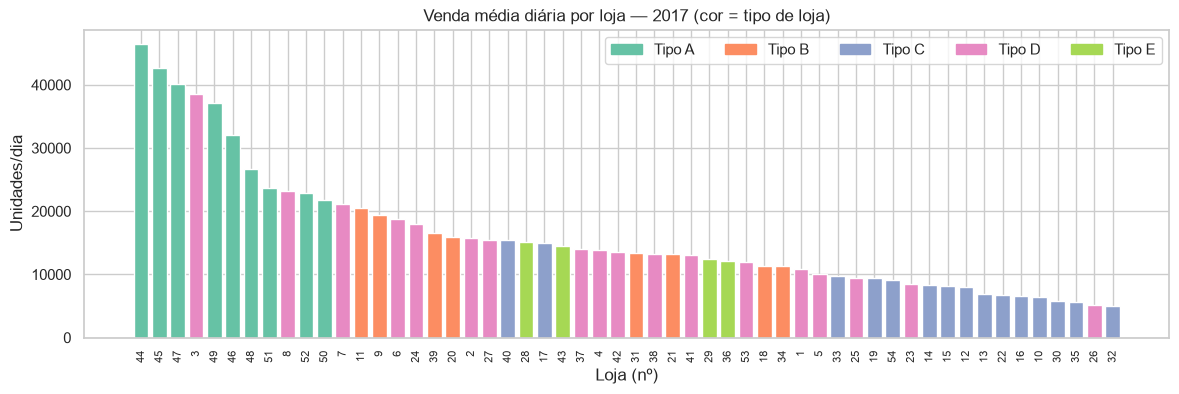

A maior loja vende 9.2x mais que a menor


,lojas,media_dia_por_loja,unidades,% do volume
store_type,,,,
A,9,"32,595","63,830,660",32.9%
B,8,"15,211","27,500,760",14.2%
C,15,"8,423","28,552,583",14.7%
D,18,"15,261","62,091,375",32.0%
E,4,"13,570","12,267,079",6.3%


In [15]:
from matplotlib.patches import Patch

# Volume total e dias de operação de cada loja
loja = (df.groupby(["store_nbr", "store_type", "city", "cluster"], observed=True)
          .agg(unidades=("unit_sales", "sum"), dias=("date", "nunique"))
          .astype({"unidades": "float64"})
          .reset_index())
loja["media_dia"] = loja["unidades"] / loja["dias"]
loja = loja.sort_values("media_dia", ascending=False)

# Gráfico: venda média diária por loja, colorida pelo tipo
tipos = sorted(loja["store_type"].astype(str).unique())
paleta = dict(zip(tipos, sns.color_palette("Set2", len(tipos))))
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(loja["store_nbr"].astype(str), loja["media_dia"],
       color=[paleta[t] for t in loja["store_type"].astype(str)])
ax.legend(handles=[Patch(color=paleta[t], label=f"Tipo {t}") for t in tipos], ncol=5)
ax.set(title="Venda média diária por loja — 2017 (cor = tipo de loja)",
       xlabel="Loja (nº)", ylabel="Unidades/dia")
ax.tick_params(axis="x", labelsize=8, rotation=90)
plt.savefig(FIG / "02_lojas_porte.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"A maior loja vende {loja['media_dia'].max() / loja['media_dia'].min():.1f}x mais que a menor")

# Resumo por tipo de loja
tipo = (loja.groupby("store_type", observed=True)
            .agg(lojas=("store_nbr", "count"),
                 media_dia_por_loja=("media_dia", "mean"),
                 unidades=("unidades", "sum")))
tipo["% do volume"] = tipo["unidades"] / tipo["unidades"].sum()
tipo.style.format({"media_dia_por_loja": "{:,.0f}", "unidades": "{:,.0f}",
                   "% do volume": "{:.1%}"})

### 💡 Insights — Porte e tipo de loja

**O que os dados mostram**
1. **Grande desigualdade de porte:** a maior loja (nº 44, ~46 mil unid./dia) vende
   **9,2x mais** que a menor (nº 32, ~5 mil unid./dia).
2. **As lojas tipo A são as "âncoras" da rede:** apenas **9 lojas (17% da rede)**
   respondem por **32,9% do volume**, com média de **~32,6 mil unid./dia** —
   quase **4x** uma loja tipo C.
3. **Lojas tipo C são as menores:** são **15 lojas (28% da rede)**, mas somam só
   **14,7% do volume** (~8,4 mil unid./dia cada).
4. **O tipo D é o mais numeroso (18 lojas) e quase empata com o A em volume
   (32,0%)** — porte médio, mas presença ampla.
5. **As 7 maiores lojas (13% da rede) somam ~30% do volume.** Entre elas aparece
   a **loja 3, tipo D**, com porte de loja A — uma exceção a investigar.

**Decisões gerenciais**
- **Distribuição e logística:** lojas A exigem **entregas diárias** e prioridade
  nas rotas do centro de distribuição; lojas C podem ter **entregas consolidadas**
  (2–3x por semana), reduzindo custo de frete.
- **Alocação de estoque:** a mesma previsão não serve para todas — o estoque de
  segurança deve ser proporcional ao volume **e** à variabilidade de cada loja.
- **Sortimento por porte:** lojas C (menores) são candidatas a sortimento enxuto,
  concentrado em itens A e B da curva ABC.
- **Expansão e benchmarking:** entender o que faz a loja 3 (tipo D) vender como
  uma loja A pode orientar melhorias nas demais lojas D.
- **Modelagem:** loja, tipo e cluster entram como *features*, e o erro será
  avaliado por tipo de loja.

In [16]:
# Volume por cidade
cidade = (loja.groupby("city", observed=True)
              .agg(lojas=("store_nbr", "count"), unidades=("unidades", "sum"))
              .sort_values("unidades", ascending=False))
cidade["% do volume"] = cidade["unidades"] / cidade["unidades"].sum()
cidade["% acumulado"] = cidade["% do volume"].cumsum()

cidade.head(10).style.format({"unidades": "{:,.0f}", "% do volume": "{:.1%}",
                              "% acumulado": "{:.1%}"})

,lojas,unidades,% do volume,% acumulado
city,,,,
Quito,18,"98,365,388",50.6%,50.6%
Guayaquil,8,"21,834,568",11.2%,61.9%
Cuenca,3,"9,991,340",5.1%,67.0%
Ambato,2,"6,821,296",3.5%,70.5%
Santo Domingo,3,"6,752,222",3.5%,74.0%
Machala,2,"6,450,850",3.3%,77.3%
Manta,2,"5,407,765",2.8%,80.1%
Cayambe,1,"4,624,950",2.4%,82.5%
Daule,1,"3,507,474",1.8%,84.3%


### 💡 Insights — Localização

**O que os dados mostram**
1. **Quito concentra metade da operação:** **18 lojas (33% da rede)** respondem por
   **50,6% do volume**. As lojas de Quito vendem em média **~5,5 milhões de unidades**
   no período — **~2x** uma loja de Guayaquil.
2. **Guayaquil, maior cidade do Equador, tem participação menor (11,2%)**, com 8 lojas
   de porte médio (~2,7 milhões de unidades cada).
3. **Duas cidades = 62% do volume; sete cidades = 80%.**
4. **Destaques de produtividade:** Cayambe e Daule têm **uma única loja cada**, mas
   vendem acima da média da rede (~3,6 milhões por loja) — mercados bem atendidos
   e com pouca concorrência interna.

**Decisões gerenciais**
- **Centro de distribuição:** a operação logística deve ser otimizada a partir de
  **Quito**, onde está metade da demanda — rotas, frota e frequência de entrega.
- **Risco concentrado:** qualquer evento em Quito (feriado local, greve, clima,
  problemas logísticos) afeta **metade das vendas** da rede. Feriados locais de
  Quito (ex.: Fundação de Quito, 6/dez) merecem planejamento específico.
- **Oportunidade de expansão:** a baixa participação em Guayaquil, dado o tamanho
  da cidade, sugere espaço para crescimento ou forte concorrência local — vale
  uma análise de mercado.
- **Modelagem:** cidade e estado entram como *features* e permitem capturar
  feriados regionais e locais.

## 8. Promoções: quanto elas realmente aumentam as vendas?
Comparar a venda média "com promoção" x "sem promoção" de forma geral é enganoso,
porque a rede tende a promover itens que **já vendem muito**.

Por isso, medimos o **uplift dentro do mesmo item e da mesma loja**:
para cada par loja-item que teve dias com e sem promoção, calculamos
`uplift = venda média com promoção ÷ venda média sem promoção − 1`.
Depois resumimos pela **mediana** de cada família (menos sensível a valores extremos).

In [17]:
# Participação das promoções no volume total
vol_promo = df.loc[df["onpromotion"] == 1, "unit_sales"].sum() / df["unit_sales"].sum()
print(f"Registros em promoção: {df['onpromotion'].mean():.1%} | "
      f"Volume vendido em promoção: {vol_promo:.1%}")

# Venda média por par loja-item, separando dias com e sem promoção
par = (df.groupby(["store_nbr", "item_nbr", "onpromotion"])["unit_sales"]
         .mean().unstack())
par.columns = ["sem_promo", "com_promo"]
par = par.dropna()                       # só pares que tiveram os dois cenários
par = par[par["sem_promo"] > 0]
par["uplift"] = par["com_promo"] / par["sem_promo"] - 1

# Junta a família e a perecibilidade de cada item
par = par.reset_index().merge(items[["item_nbr", "family", "perishable"]], on="item_nbr")
print(f"Pares loja-item comparáveis: {len(par):,}")
print(f"Uplift mediano geral: {par['uplift'].median():+.1%}")

# Resumo por família (apenas famílias com pelo menos 100 pares)
promo_fam = (par.groupby("family")
                .agg(pares=("uplift", "size"),
                     uplift_mediano=("uplift", "median"),
                     perecivel=("perishable", "max")))
promo_fam["% registros em promoção"] = (df.groupby("family", observed=True)["onpromotion"]
                                          .mean().reindex(promo_fam.index))
promo_fam = promo_fam[promo_fam["pares"] >= 100].sort_values("uplift_mediano", ascending=False)

Registros em promoção: 11.5% | Volume vendido em promoção: 19.4%
Pares loja-item comparáveis: 99,796
Uplift mediano geral: +33.3%


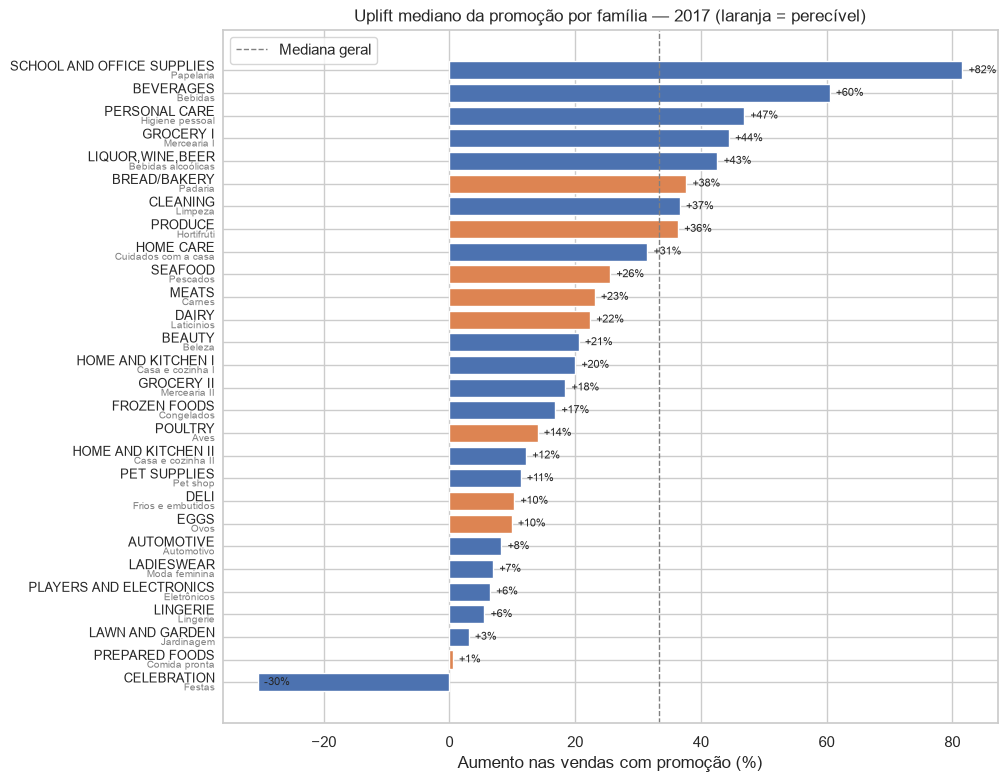

,pares,uplift_mediano,perecivel,% registros em promoção
family,,,,
SCHOOL AND OFFICE SUPPLIESPapelaria,285,+81.6%,0,40.2%
BEVERAGESBebidas,13908,+60.5%,0,8.2%
PERSONAL CAREHigiene pessoal,3971,+46.9%,0,12.8%
GROCERY IMercearia I,27554,+44.4%,0,8.2%
"LIQUOR,WINE,BEERBebidas alcoólicas",1267,+42.6%,0,14.0%
BREAD/BAKERYPadaria,3508,+37.7%,1,14.2%
CLEANINGLimpeza,10196,+36.6%,0,10.1%
PRODUCEHortifrúti,10879,+36.3%,1,17.6%
HOME CARECuidados com a casa,2904,+31.5%,0,15.1%


In [21]:
# Recarrega o src/data.py para pegar as alterações sem reiniciar o kernel
import importlib, src.data
importlib.reload(src.data)
from src.data import FAMILY_PT
import matplotlib.transforms as mtransforms

# Ordena do menor para o maior (para o maior ficar no topo do gráfico)
plot = promo_fam.iloc[::-1]
y = np.arange(len(plot))
cores = ["C1" if p == 1 else "C0" for p in plot["perecivel"]]

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(y, plot["uplift_mediano"] * 100, color=cores)
ax.axvline(par["uplift"].median() * 100, color="gray", ls="--", lw=1,
           label="Mediana geral")

# Valores ao lado das barras
for i, v in enumerate(plot["uplift_mediano"] * 100):
    ax.text(v + 1, i, f"{v:+.0f}%", va="center", fontsize=8)

# Rótulos em duas linhas: nome original (normal) + tradução (menor, cinza)
ax.set_yticks(y)
ax.set_yticklabels([])
ax.tick_params(axis="y", length=0)
trans = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)
for i, fam in enumerate(plot.index):
    ax.text(-0.01, i + 0.15, fam, transform=trans,
            ha="right", va="center", fontsize=9)
    ax.text(-0.01, i - 0.25, FAMILY_PT.get(fam, ""), transform=trans,
            ha="right", va="center", fontsize=7, color="gray")

ax.set(title="Uplift mediano da promoção por família — 2017 (laranja = perecível)",
       xlabel="Aumento nas vendas com promoção (%)")
ax.legend()
plt.savefig(FIG / "02_promocoes_uplift.png", dpi=120, bbox_inches="tight")
plt.show()

# Tabela: nome original + tradução menor e cinza na mesma célula
promo_fam.style.format(
    {"uplift_mediano": "{:+.1%}", "% registros em promoção": "{:.1%}"}
).format_index(
    lambda f: f"{f}<br><small style='color:gray'>{FAMILY_PT.get(f, '')}</small>",
    axis=0,
)

### 💡 Insights — Promoções

**O que os dados mostram**
1. **As promoções têm peso relevante no negócio:** estão em **11,5% dos registros**,
   mas respondem por **19,4% do volume vendido** — um registro em promoção vende,
   em média, **~1,7x** um registro comum.
2. **Comparando o mesmo item na mesma loja** (99.796 pares loja-item com e sem
   promoção), **a promoção aumenta as vendas em +33,3%** (mediana). O efeito varia
   muito entre famílias — de **+82%** a **−30%**.
3. **Não perecíveis "estocáveis" respondem mais:** BEVERAGES <small>(bebidas)</small> **+60%**,
   PERSONAL CARE <small>(higiene pessoal)</small> **+47%**, GROCERY I <small>(mercearia)</small>
   **+44%** e LIQUOR,WINE,BEER <small>(bebidas alcoólicas)</small> **+43%**. O consumidor
   aproveita o preço para **estocar em casa**.
4. **Perecíveis respondem menos**, porque não dá para estocar: DAIRY <small>(laticínios)</small>
   +22%, POULTRY <small>(aves)</small> +14%, EGGS <small>(ovos)</small> +10%,
   PREPARED FOODS <small>(comida pronta)</small> +1%. Exceções: BREAD/BAKERY
   <small>(padaria)</small> +38% e PRODUCE <small>(hortifrúti)</small> +36%.
5. **SCHOOL AND OFFICE SUPPLIES** <small>(papelaria)</small> **lidera (+82%)** —
   provavelmente porque as promoções coincidem com a **volta às aulas** (sazonalidade
   e promoção se misturam).
6. **CELEBRATION** <small>(festas)</small> **tem uplift negativo (−30%)**: a promoção
   parece ser usada para **liquidar sobras** depois das datas comemorativas, quando a
   demanda já caiu.
7. **Em ~7 famílias o efeito é inferior a +10%** — a promoção praticamente não muda
   o comportamento de compra.

> ⚠️ Limitações: o uplift é uma **associação**, não um efeito causal isolado — não
> controla sazonalidade, feriados ou preço praticado, e considera apenas os dias com
> venda registrada. A diferença entre ~1,7x (geral) e +33% (mesmo item/loja) mostra
> que a rede tende a **promover itens que já vendem muito**.

**Decisões gerenciais**
- **Concentrar a verba promocional em BEVERAGES** <small>(bebidas)</small>: combina
  **alto uplift (+60%)** com **alto volume (22,6% das vendas)** — é a maior alavanca.
- **Medir o "efeito ressaca":** em itens estocáveis, parte do ganho pode ser apenas
  **venda antecipada** (o cliente deixa de comprar nas semanas seguintes). Avaliar o
  período pós-promoção antes de concluir que a ação dá lucro.
- **Perecíveis: promoção como ferramenta antiperda**, não de crescimento — usar
  PRODUCE <small>(hortifrúti)</small> e BREAD/BAKERY <small>(padaria)</small>
  (+36–38%) para **escoar excesso** próximo ao vencimento.
- **Rever ou cortar promoções** nas famílias com uplift < 10%: o desconto reduz
  margem sem gerar volume.
- **Previsão:** quando houver promoção planejada, a previsão deve ser ajustada pelo
  uplift **específico da família**. Como as promoções são conhecidas com antecedência,
  `onpromotion` será uma *feature* central do modelo.

## 9. Feriados e eventos nacionais
O Equador tem feriados **nacionais, regionais e locais**, além de feriados
**transferidos** (celebrados em outra data) e "pontes". Aqui analisamos os
**feriados e eventos nacionais de 2017**, comparando a venda do dia e da véspera
com um dia normal.

Usamos o índice diário **ajustado pelo dia da semana** (seção 5), em que
**100 = um dia típico**. Assim, um feriado que cai no domingo não parece forte
só por ser domingo.

In [24]:
# Índice diário ajustado pelo dia da semana (100 = dia típico)
idx = daily_adj / daily_adj.mean() * 100

# Feriados/eventos NACIONAIS de 2017 efetivamente celebrados
# (transferred=True marca a data original que foi "movida"; "Work Day" é dia útil compensatório)
hol = holidays[(holidays["date"].dt.year == 2017) & (~holidays["transferred"])]
nac = (hol[(hol["locale"] == "National") & (hol["type"] != "Work Day")]
         .drop_duplicates("date")
         .set_index("date")[["type", "description"]])
nac = nac[nac.index <= idx.index.max()]

nac["índice do dia"] = idx.reindex(nac.index).values
nac["índice da véspera"] = idx.reindex(nac.index - pd.Timedelta(days=1)).values

nac.style.format({"índice do dia": "{:.0f}", "índice da véspera": "{:.0f}"}, na_rep="—") \
   .format_index(lambda d: d.strftime("%d/%m/%Y"), axis=0)

,type,description,índice do dia,índice da véspera
date,,,,
02/01/2017,Transfer,Traslado Primer dia del ano,169,—
27/02/2017,Holiday,Carnaval,90,71
28/02/2017,Holiday,Carnaval,123,90
14/04/2017,Holiday,Viernes Santo,92,110
01/05/2017,Holiday,Dia del Trabajo,158,95
13/05/2017,Additional,Dia de la Madre-1,108,95
14/05/2017,Event,Dia de la Madre,81,108
26/05/2017,Transfer,Traslado Batalla de Pichincha,123,92
11/08/2017,Transfer,Traslado Primer Grito de Independencia,103,97


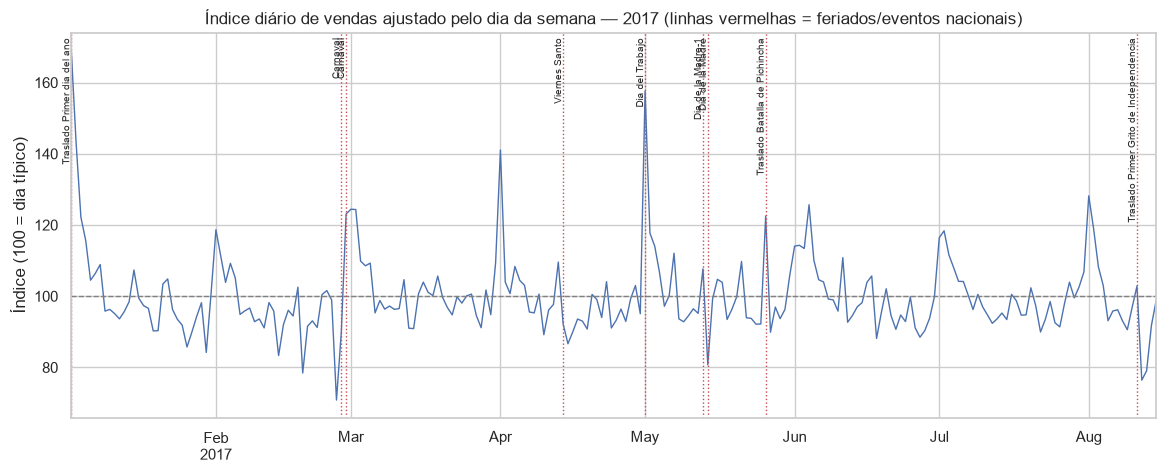

,Índice médio,Nº de dias
Dia normal,99.5,211.0
Feriado/evento,116.2,9.0
Véspera,93.3,6.0


In [25]:
# Gráfico: índice diário com os feriados nacionais marcados
fig, ax = plt.subplots(figsize=(14, 5))
idx.plot(ax=ax, lw=1, color="C0")
ax.axhline(100, color="gray", ls="--", lw=1)
topo = idx.max() * 1.02
for d, row in nac.iterrows():
    ax.axvline(d, color="C3", ls=":", lw=1)
    ax.text(d, topo, row["description"], rotation=90, va="top", ha="right", fontsize=7)
ax.set(title="Índice diário de vendas ajustado pelo dia da semana — 2017 (linhas vermelhas = feriados/eventos nacionais)",
       xlabel="", ylabel="Índice (100 = dia típico)")
plt.savefig(FIG / "02_feriados.png", dpi=120, bbox_inches="tight")
plt.show()

# Resumo: feriado x véspera x dia normal
dias_fer = idx.index.isin(nac.index)
dias_vesp = idx.index.isin(nac.index - pd.Timedelta(days=1)) & ~dias_fer
classe_dia = np.select([dias_fer, dias_vesp], ["Feriado/evento", "Véspera"], "Dia normal")

resumo_fer = idx.groupby(classe_dia).agg(["mean", "count"])
resumo_fer.columns = ["Índice médio", "Nº de dias"]
resumo_fer.astype("float64").round(1)

### 💡 Insights — Feriados e eventos nacionais

**O que os dados mostram**
1. **Em média, feriados/eventos nacionais vendem ~17% acima de um dia típico**
   (índice 116 contra 99,5), mas o efeito **varia muito de um feriado para outro**:

   | Data | Feriado/evento | Índice | Leitura |
   |---|---|---|---|
   | 02/01 | Traslado Primer día del año <small>(Ano-Novo transferido)</small> | **169** | reabertura após 01/01 fechado: demanda reprimida |
   | 01/05 | Día del Trabajo <small>(Dia do Trabalho)</small> | **158** | o feriado mais forte do período |
   | 28/02 | Carnaval (2º dia) | 123 | recuperação após um início fraco |
   | 26/05 | Traslado Batalla de Pichincha <small>(feriado transferido)</small> | 123 | sexta-feira de **feriado prolongado** |
   | 13/05 | Día de la Madre −1 <small>(véspera do Dia das Mães)</small> | 108 | compras concentradas no sábado |
   | 14/04 | Viernes Santo <small>(Sexta-feira Santa)</small> | 92 | a véspera (quinta) vende mais: **110** |
   | 27/02 | Carnaval (1º dia) | 90 | a véspera (domingo) foi das mais fracas do ano: **71** |
   | 14/05 | Día de la Madre <small>(Dia das Mães)</small> | **81** | famílias comem fora / compram presentes, não supermercado |

2. **Vésperas não são sistematicamente mais fortes** (índice médio 93) — exceto
   antes de feriados com recolhimento em casa, como a Sexta-feira Santa.
3. **O Carnaval desloca a demanda:** queda forte antes (viagens) e alta no 2º dia.
4. **Feriados transferidos para sexta-feira** criam fins de semana prolongados
   com vendas acima da média.
5. Os outros picos do gráfico fora dos feriados (início de abril, junho e agosto)
   coincidem com o **início do mês** — reforçando o efeito do pagamento (seção 5).

> Obs.: apenas 9 feriados/eventos nacionais no período, então cada data deve ser
> analisada individualmente. Feriados regionais e locais (ex.: Quito) não foram
> incluídos nesta análise.

**Decisões gerenciais**
- **Calendário promocional e de abastecimento por feriado**, e não uma regra única:
  - **Reforço forte (+50–70%)** na reabertura pós-Ano-Novo e no Dia do Trabalho.
  - **Reforço moderado (+20%)** em sextas de feriado prolongado e no 2º dia de Carnaval.
  - **Redução de pedidos de perecíveis** na véspera do Carnaval e no Dia das Mães.
- **Dia das Mães:** antecipar ações para o **sábado** (+8%) — o domingo vende
  ~20% menos que um dia típico.
- **Escala de equipe** alinhada ao padrão de cada data, evitando reforço em
  feriados que, na verdade, vendem menos.
- **Modelagem:** usar *features* de feriado **por tipo** (Holiday, Transfer,
  Event, Additional) e marcar dias de loja fechada e de reabertura, em vez de
  uma única variável "é feriado".